In [1]:
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import gaussian_kde

import boto3
import json
import yaml
import openesm
from pathlib import Path
from io import BytesIO

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
sns.set_style("whitegrid")

In [2]:
dataset = openesm.get_dataset("0073_sicorello")

✓ Loading dataset 0073 version 2.0.0

ℹ For full reproducibility, use:
openesm.get_dataset("0073", metadata_version="2.0.0", version="2.0.0")


📊 OpenESM Dataset: 0073
   • Version: 2.0.0
   • Authors: Sicorello et al. (2024)
   • Paper DOI: https://doi.org/10.31234/osf.io/8mzvu
   • License: CC BY-NC 4.0
   • Data: A DataFrame with 227 participants and 60 maximum time points per 
participant

ℹ️  Use dataset.cite() for citation information.
ℹ️  Use dataset.notes() for additional information about the dataset.
ℹ️  Please ensure you follow the license terms for this dataset.




In [3]:
df = dataset.data.to_pandas()

In [4]:
df.shape

(8628, 45)

In [5]:
df.columns

Index(['id', 'day', 'beep', 'date', 'participant_timezone', 'export_timezone',
       'created', 'scheduled', 'started', 'completed', 'expired', 'uploaded',
       'guilty_emotion', 'out_of_control', 'embarrassed_emotion',
       'negative_self_thoughts', 'emotion_confusion', 'ashamed_emotion',
       'task_difficulty', 'prolonged_emotion_expectation', 'annoyed_at_self',
       'behavior_control_difficulty', 'confused_emotions', 'down_expectation',
       'emotions_out_of_control', 'annoyed_at_self_emotion', 'weak_emotion',
       'overwhelming_emotions', 'affect_grid_x', 'affect_grid_y',
       'seek_contact_affect', 'others_perspective_giving', 'received_comfort',
       'received_coping_examples', 'negative_event', 'positive_event',
       'impulse_contact_emotion_regulation', 'impulse_self_regulation',
       'quest_duration', 'time', 'emotion_awareness', 'acknowledge_emotions',
       'care_about_emotions', 'emotion_exploration', 'emotions_valid'],
      dtype='str')

In [6]:
df.isna().sum().sort_values()

id                                       0
day                                      0
beep                                     0
date                                     0
participant_timezone                     0
export_timezone                          0
created                                  0
scheduled                                0
started                                  0
completed                                0
uploaded                                 0
guilty_emotion                           0
embarrassed_emotion                      0
out_of_control                           0
negative_self_thoughts                   0
emotion_confusion                        0
emotions_out_of_control                  0
ashamed_emotion                          0
task_difficulty                          0
prolonged_emotion_expectation            0
annoyed_at_self                          0
behavior_control_difficulty              0
confused_emotions                        0
down_expect

In [7]:
df.head()

,id,day,beep,date,participant_timezone,export_timezone,created,scheduled,started,completed,expired,uploaded,guilty_emotion,out_of_control,embarrassed_emotion,negative_self_thoughts,emotion_confusion,ashamed_emotion,task_difficulty,prolonged_emotion_expectation,annoyed_at_self,behavior_control_difficulty,confused_emotions,down_expectation,emotions_out_of_control,annoyed_at_self_emotion,weak_emotion,overwhelming_emotions,affect_grid_x,affect_grid_y,seek_contact_affect,others_perspective_giving,received_comfort,received_coping_examples,negative_event,positive_event,impulse_contact_emotion_regulation,impulse_self_regulation,quest_duration,time,emotion_awareness,acknowledge_emotions,care_about_emotions,emotion_exploration,emotions_valid
0,s003987858,2,1,2023-09-03,Europe/Berlin,Europe/Berlin,2023-09-03T10:25:00Z,2023-09-03T10:25:00Z,2023-09-03 10:25:00,2023-09-03 10:28:00,NaN,2023-09-03T10:28:00Z,1,1,1,1,1,1,1,3,1,1,1,1,1,1,1,1,7.0,7.0,2,1,1,1,1,6,1.0,4,180,10:28:00,2,2,2,2,1
1,s003987858,3,1,2023-09-04,Europe/Berlin,Europe/Berlin,2023-09-04T10:15:00Z,2023-09-04T10:15:00Z,2023-09-04 10:15:00,2023-09-04 10:17:00,NaN,2023-09-04T10:17:00Z,1,1,1,1,3,1,1,2,1,1,2,1,1,1,1,1,7.0,7.0,4,1,1,1,2,5,4.0,3,120,10:17:00,2,3,2,2,2
2,s003987858,2,2,2023-09-03,Europe/Berlin,Europe/Berlin,2023-09-03T12:12:00Z,2023-09-03T12:12:00Z,2023-09-03 12:12:00,2023-09-03 12:14:00,NaN,2023-09-03T12:14:00Z,1,1,1,1,2,1,2,3,1,1,1,1,1,1,1,1,7.0,7.0,1,1,1,1,1,1,1.0,4,120,12:14:00,2,2,2,3,1
3,s003987858,8,6,2023-09-09,Europe/Berlin,Europe/Berlin,2023-09-09T17:22:00Z,2023-09-09T17:22:00Z,2023-09-09 17:22:00,2023-09-09 17:23:00,NaN,2023-09-09T17:23:00Z,1,1,1,1,1,1,1,3,1,1,1,1,1,1,1,1,9.0,9.0,3,1,1,1,1,3,5.0,1,60,17:23:00,1,2,2,2,1
4,s003987858,9,5,2023-09-10,Europe/Berlin,Europe/Berlin,2023-09-10T17:13:00Z,2023-09-10T17:09:00Z,2023-09-10 17:13:00,2023-09-10 17:16:00,NaN,2023-09-10T17:16:00Z,1,1,1,1,1,1,1,2,1,1,1,1,1,1,1,1,8.0,8.0,3,1,1,1,1,5,4.0,2,180,17:16:00,2,2,2,3,1


In [8]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

timestamp_cols = [
    "created",
    "scheduled",
    "started",
    "completed",
    "uploaded"
]

for col in timestamp_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce", utc=True)

df["time"] = pd.to_datetime(
    df["time"],
    format="%H:%M:%S",
    errors="coerce"
).dt.time

df["time_minutes"] = (
    pd.to_timedelta(df["time"].astype(str)).dt.total_seconds() / 60
)

df["time_to_complete"] = (
    df["completed"] - df["started"]
).dt.total_seconds()

df["time_to_complete_minutes"] = df["time_to_complete"] / 60

In [9]:
df.dtypes

id                                                    str
day                                                 int64
beep                                                int64
date                                       datetime64[us]
participant_timezone                                  str
export_timezone                                       str
created                               datetime64[us, UTC]
scheduled                             datetime64[us, UTC]
started                               datetime64[us, UTC]
completed                             datetime64[us, UTC]
expired                                               str
uploaded                              datetime64[us, UTC]
guilty_emotion                                      int64
out_of_control                                      int64
embarrassed_emotion                                 int64
negative_self_thoughts                              int64
emotion_confusion                                   int64
ashamed_emotio

In [10]:
sicorello_metadata = dataset.metadata

In [11]:
type(sicorello_metadata)

dict

In [12]:
sicorello_metadata.keys()

dict_keys(['dataset_id', 'first_author', 'year', 'reference_a', 'reference_b', 'paper_doi', 'zenodo_doi', 'license', 'link_to_data', 'link_to_codebook', 'link_to_code', 'n_participants', 'n_time_points', 'n_days', 'n_beeps_per_day', 'passive_data_available', 'cross_sectional_available', 'topics', 'implicit_missingness', 'raw_time_stamp', 'sampling_scheme', 'participants', 'coding_file', 'additional_comments', 'features'])

In [13]:
sicorello_features = {
    "dataset_id": sicorello_metadata["dataset_id"],
    "first_author": sicorello_metadata["first_author"],
    "year": sicorello_metadata["year"],
    "n_participants": sicorello_metadata["n_participants"],
    "n_time_points": sicorello_metadata["n_time_points"],
    "n_days": sicorello_metadata["n_days"],
    "n_beeps_per_day": sicorello_metadata["n_beeps_per_day"],
    "passive_data_available": sicorello_metadata["passive_data_available"],
    "cross_sectional_available": sicorello_metadata["cross_sectional_available"],
    "topics": sicorello_metadata["topics"],
    "implicit_missingness": sicorello_metadata["implicit_missingness"],
    "raw_time_stamp": sicorello_metadata["raw_time_stamp"],
    "sampling_scheme": sicorello_metadata["sampling_scheme"],
    "features": sicorello_metadata["features"],
}

In [14]:
for key in [
    "year",
    "n_participants",
    "n_days",
    "n_time_points",
    "n_beeps_per_day"
]:
    print(f"{key}: {sicorello_features[key]}")

year: 2024
n_participants: 227
n_days: 10
n_time_points: 60
n_beeps_per_day: 6


In [15]:
numeric_fields = [
    "n_participants",
    "n_time_points",
    "n_days",
    "n_beeps_per_day",
]

for field in numeric_fields:
    sicorello_features[field] = int(sicorello_features[field])

In [16]:
theoretical_rows = (
    sicorello_features["n_participants"]
    * sicorello_features["n_days"]
    * sicorello_features["n_beeps_per_day"]
)

actual_rows = len(df)
difference = theoretical_rows - actual_rows

print(f"Theoretical dataset size: {theoretical_rows:,} rows")
print(f"Actual dataset size:      {actual_rows:,} rows")
print(f"Difference:               {difference:,} rows")
print(f"Difference (%):           {difference / theoretical_rows * 100:.2f}%")

Theoretical dataset size: 13,620 rows
Actual dataset size:      8,628 rows
Difference:               4,992 rows
Difference (%):           36.65%


In [17]:
responses_per_participant = df.groupby("id").size()
response_distribution = responses_per_participant.value_counts().sort_index()

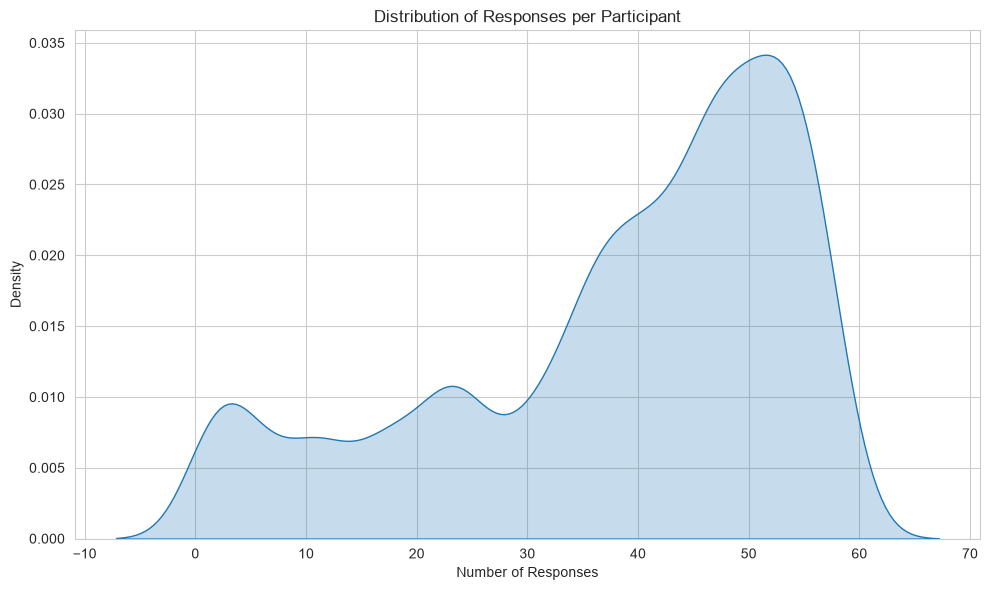

In [18]:
plt.figure(figsize=(10, 6))

sns.kdeplot(
    data=responses_per_participant,
    fill=True,
    bw_adjust=0.5
)

plt.xlabel("Number of Responses")
plt.ylabel("Density")
plt.title("Distribution of Responses per Participant")
plt.tight_layout()
plt.show()

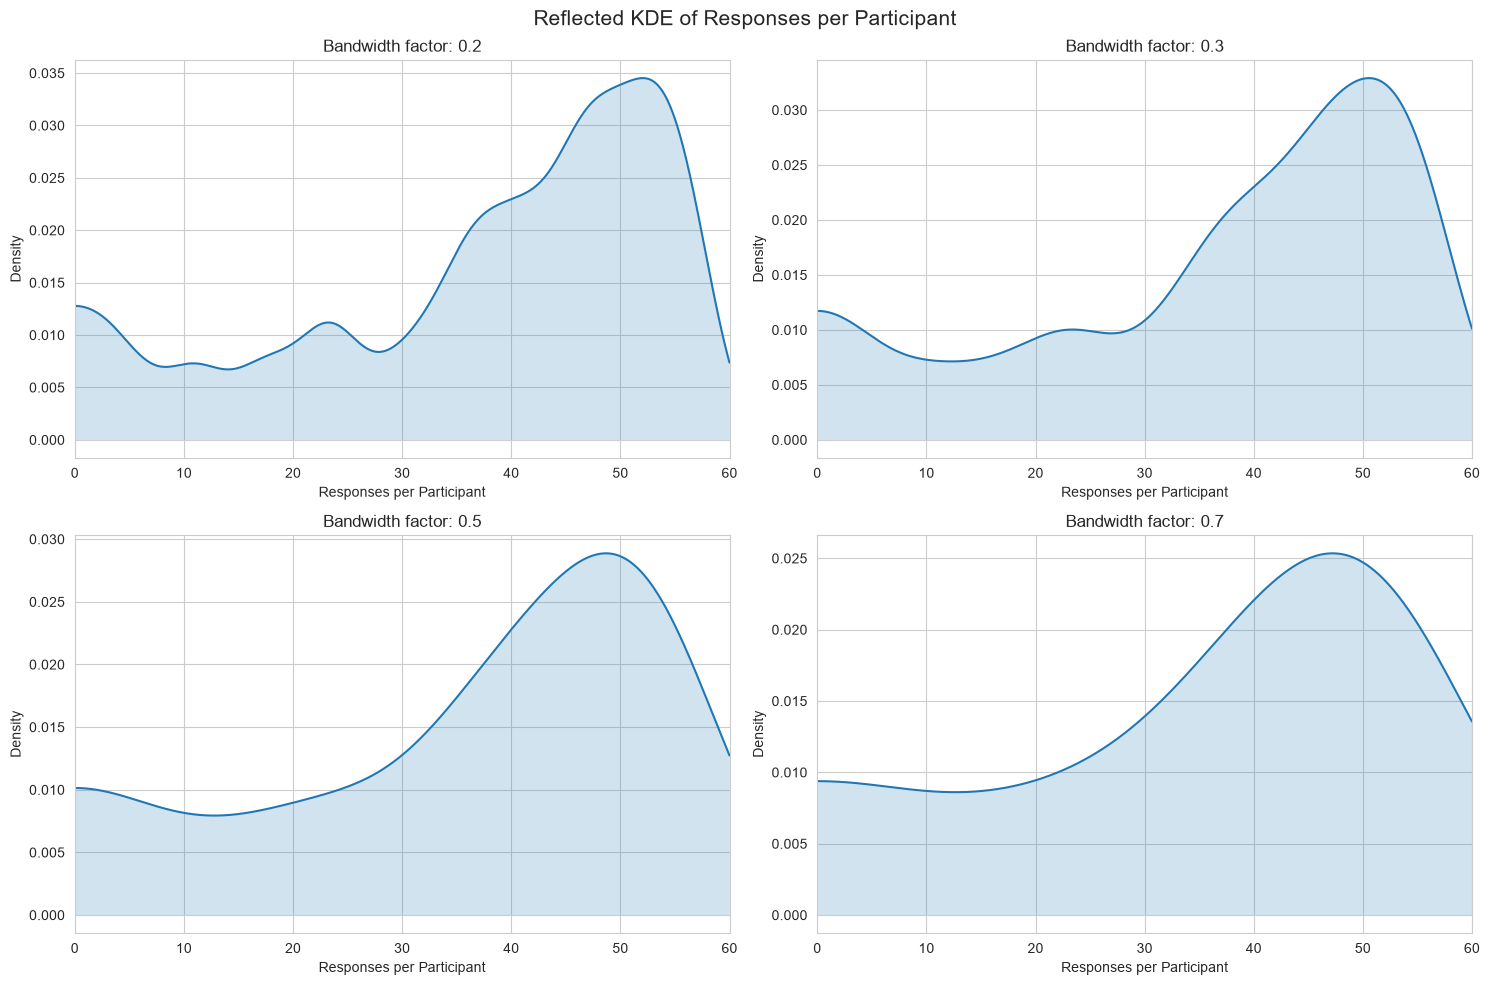

In [19]:
x = responses_per_participant.to_numpy(dtype=float)
x_reflected = np.concatenate([x, -x])
base_kde = gaussian_kde(x_reflected, bw_method="scott")
x_grid = np.linspace(0, 60, 1000)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, factor in zip(axes.flat, [0.2, 0.3, 0.5, 0.7]):
    kde = gaussian_kde(
        x_reflected,
        bw_method=base_kde.factor * factor
    )

    density = 2 * kde(x_grid)

    ax.plot(x_grid, density)
    ax.fill_between(x_grid, density, alpha=0.2)
    ax.set_title(f"Bandwidth factor: {factor}")
    ax.set_xlabel("Responses per Participant")
    ax.set_ylabel("Density")
    ax.set_xlim(0, 60)

fig.suptitle(
    "Reflected KDE of Responses per Participant",
    fontsize=15
)

plt.tight_layout()
plt.show()

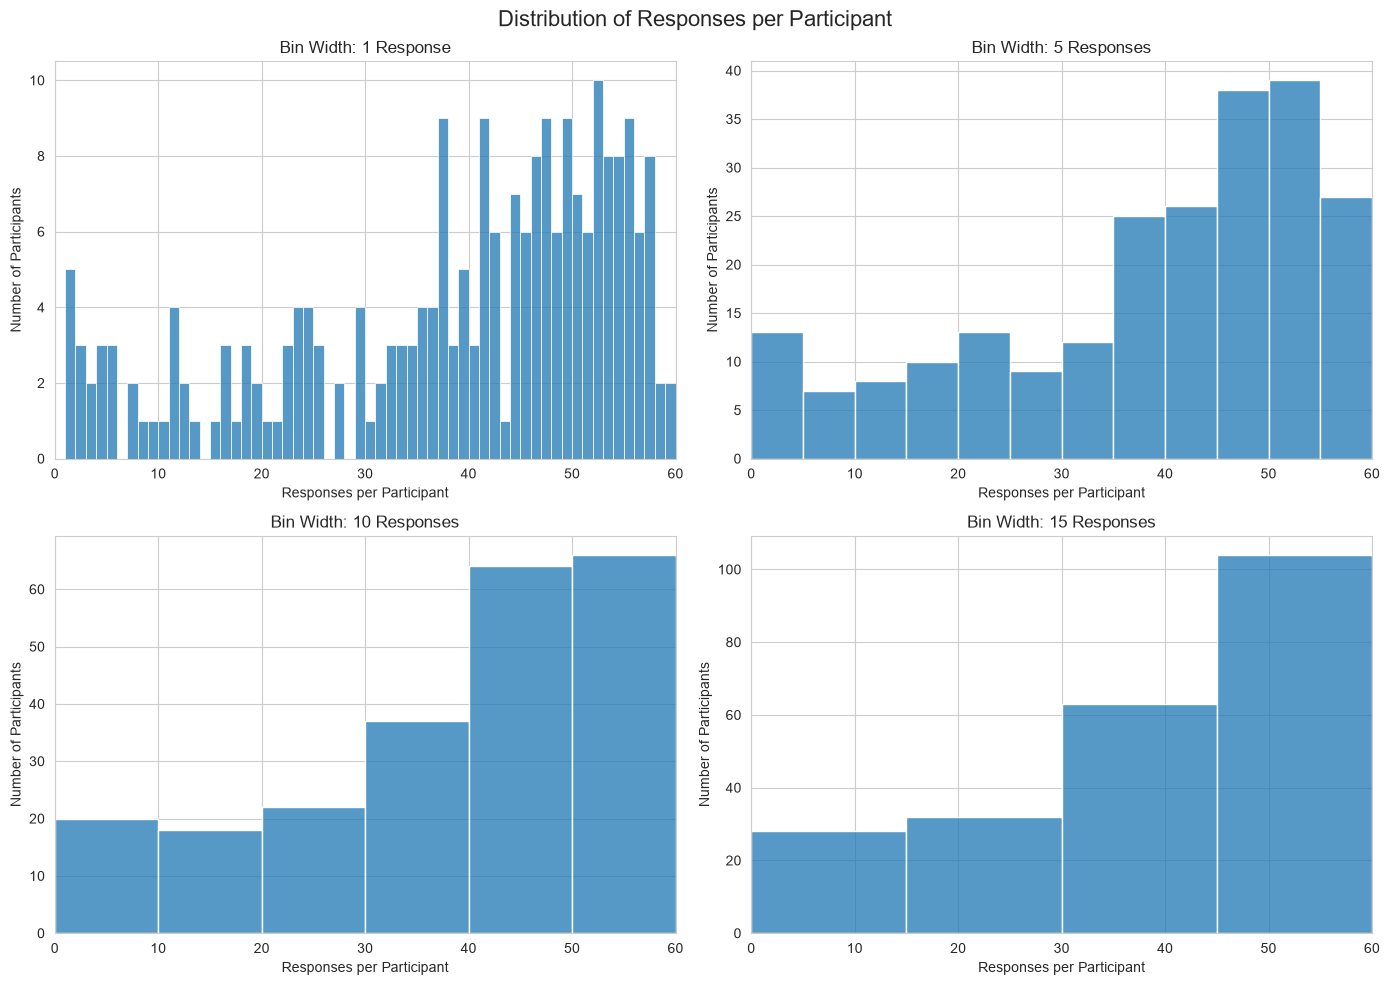

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

bin_widths = [1, 5, 10, 15]

for ax, width in zip(axes.flat, bin_widths):
    sns.histplot(
        x=responses_per_participant,
        binwidth=width,
        binrange=(0, 60),
        ax=ax
    )

    ax.set_title(f"Bin Width: {width} Response{'s' if width > 1 else ''}")
    ax.set_xlabel("Responses per Participant")
    ax.set_ylabel("Number of Participants")
    ax.set_xlim(0, 60)

plt.suptitle(
    "Distribution of Responses per Participant",
    fontsize=16
)
plt.tight_layout()
plt.show()

In [ ]:
#

responded
0    4994
1    8626
Name: count, dtype: int64


In [22]:
duplicates = df.duplicated(
    subset=["id", "day", "beep"],
    keep=False
)

print("Rows involved in duplicate combinations:", duplicates.sum())
print(
    df.loc[duplicates, ["id", "day", "beep"]]
    .sort_values(["id", "day", "beep"])
)

print("\nUnique participants:", df["id"].nunique())
print("Days:", sorted(df["day"].dropna().unique()))
print("Beeps:", sorted(df["beep"].dropna().unique()))

Rows involved in duplicate combinations: 0
Empty DataFrame
Columns: [id, day, beep]
Index: []

Unique participants: 227
Days: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
Beeps: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]


In [23]:
df["beep"].value_counts().sort_index()

beep
1    2006
2    1878
3    1711
4    1452
5    1051
6     528
7       1
8       1
Name: count, dtype: int64

In [24]:
unusual_beeps = df[df["beep"].isin([7, 8])]

display(unusual_beeps)

,id,day,beep,date,participant_timezone,export_timezone,created,scheduled,started,completed,expired,uploaded,guilty_emotion,out_of_control,embarrassed_emotion,negative_self_thoughts,emotion_confusion,ashamed_emotion,task_difficulty,prolonged_emotion_expectation,annoyed_at_self,behavior_control_difficulty,confused_emotions,down_expectation,emotions_out_of_control,annoyed_at_self_emotion,weak_emotion,overwhelming_emotions,affect_grid_x,affect_grid_y,seek_contact_affect,others_perspective_giving,received_comfort,received_coping_examples,negative_event,positive_event,impulse_contact_emotion_regulation,impulse_self_regulation,quest_duration,time,emotion_awareness,acknowledge_emotions,care_about_emotions,emotion_exploration,emotions_valid,time_minutes,time_to_complete,time_to_complete_minutes
30,s003987858,8,7,2023-09-09,Europe/Berlin,Europe/Berlin,2023-09-09 17:50:00+00:00,2023-09-09 17:21:00+00:00,2023-09-09 17:50:00+00:00,2023-09-09 17:51:00+00:00,NaN,2023-09-09 17:51:00+00:00,1,1,1,1,1,1,1,3,1,1,1,1,1,1,1,1,8.0,8.0,3,1,1,1,1,2,5.0,1,60,17:51:00,2,2,1,2,1,1071.0,60.0,1.0
31,s003987858,8,8,2023-09-09,Europe/Berlin,Europe/Berlin,2023-09-09 19:03:00+00:00,2023-09-09 19:03:00+00:00,2023-09-09 19:03:00+00:00,2023-09-09 19:04:00+00:00,NaN,2023-09-09 19:04:00+00:00,1,1,1,1,1,1,1,3,1,1,1,1,1,1,1,1,8.0,8.0,2,1,1,1,1,4,5.0,3,60,19:04:00,2,2,2,2,1,1144.0,60.0,1.0


In [25]:
df = df[~df["beep"].isin([7, 8])].copy()

In [26]:
nonresponses = schedule[schedule["responded"] == 0]

In [27]:
nonresponses

,id,day,beep,responded
5,s003987858,1,6,0
11,s003987858,2,6,0
46,s003987858,8,5,0
53,s003987858,9,6,0
57,s003987858,10,4,0
...,...,...,...,...
13615,s985659374,10,2,0
13616,s985659374,10,3,0
13617,s985659374,10,4,0
13618,s985659374,10,5,0


In [28]:
expected_rows = len(schedule)
actual_responses = schedule["responded"].sum()
nonresponses = (schedule["responded"] == 0).sum()

print(f"Expected prompts:  {expected_rows:,}")
print(f"Observed responses: {actual_responses:,}")
print(f"Nonresponses:        {nonresponses:,}")
print(f"Response rate:       {actual_responses / expected_rows:.2%}")
print(f"Nonresponse rate:    {nonresponses / expected_rows:.2%}")

Expected prompts:  13,620
Observed responses: 8,626
Nonresponses:        4,994
Response rate:       63.33%
Nonresponse rate:    36.67%


In [29]:
display(
    df[df["beep"].isin([7, 8])]
)

,id,day,beep,date,participant_timezone,export_timezone,created,scheduled,started,completed,expired,uploaded,guilty_emotion,out_of_control,embarrassed_emotion,negative_self_thoughts,emotion_confusion,ashamed_emotion,task_difficulty,prolonged_emotion_expectation,annoyed_at_self,behavior_control_difficulty,confused_emotions,down_expectation,emotions_out_of_control,annoyed_at_self_emotion,weak_emotion,overwhelming_emotions,affect_grid_x,affect_grid_y,seek_contact_affect,others_perspective_giving,received_comfort,received_coping_examples,negative_event,positive_event,impulse_contact_emotion_regulation,impulse_self_regulation,quest_duration,time,emotion_awareness,acknowledge_emotions,care_about_emotions,emotion_exploration,emotions_valid,time_minutes,time_to_complete,time_to_complete_minutes


In [30]:
keys = ["id", "day", "beep"]

observed = df.copy()

model_df = schedule[keys].merge(
    observed,
    on=keys,
    how="left",
    validate="one_to_one",
    indicator=True
)

model_df["responded"] = (
    model_df["_merge"] == "both"
).astype(int)

model_df = model_df.drop(columns="_merge")

In [31]:
model_df.head()

,id,day,beep,date,participant_timezone,export_timezone,created,scheduled,started,completed,expired,uploaded,guilty_emotion,out_of_control,embarrassed_emotion,negative_self_thoughts,emotion_confusion,ashamed_emotion,task_difficulty,prolonged_emotion_expectation,annoyed_at_self,behavior_control_difficulty,confused_emotions,down_expectation,emotions_out_of_control,annoyed_at_self_emotion,weak_emotion,overwhelming_emotions,affect_grid_x,affect_grid_y,seek_contact_affect,others_perspective_giving,received_comfort,received_coping_examples,negative_event,positive_event,impulse_contact_emotion_regulation,impulse_self_regulation,quest_duration,time,emotion_awareness,acknowledge_emotions,care_about_emotions,emotion_exploration,emotions_valid,time_minutes,time_to_complete,time_to_complete_minutes,responded
0,s003987858,1,1,2023-09-02,Europe/Berlin,Europe/Berlin,2023-09-02 10:39:00+00:00,2023-09-02 10:12:00+00:00,2023-09-02 10:39:00+00:00,2023-09-02 10:42:00+00:00,NaN,2023-09-02 10:42:00+00:00,1.0,1.0,1.0,1.0,1.0,1.0,2.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,9.0,9.0,3.0,1.0,1.0,1.0,1.0,5.0,1.0,5.0,180.0,10:42:00,3.0,1.0,1.0,2.0,1.0,642.0,180.0,3.0,1
1,s003987858,1,2,2023-09-02,Europe/Berlin,Europe/Berlin,2023-09-02 12:00:00+00:00,2023-09-02 11:58:00+00:00,2023-09-02 12:00:00+00:00,2023-09-02 12:02:00+00:00,NaN,2023-09-02 12:02:00+00:00,1.0,1.0,1.0,1.0,1.0,1.0,1.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,8.0,9.0,4.0,1.0,1.0,1.0,1.0,4.0,1.0,5.0,120.0,12:02:00,4.0,2.0,1.0,4.0,1.0,722.0,120.0,2.0,1
2,s003987858,1,3,2023-09-02,Europe/Berlin,Europe/Berlin,2023-09-02 13:38:00+00:00,2023-09-02 13:38:00+00:00,2023-09-02 13:38:00+00:00,2023-09-02 13:40:00+00:00,NaN,2023-09-02 13:40:00+00:00,1.0,1.0,1.0,1.0,2.0,1.0,3.0,3.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,9.0,7.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,4.0,120.0,13:40:00,2.0,2.0,2.0,1.0,1.0,820.0,120.0,2.0,1
3,s003987858,1,4,2023-09-02,Europe/Berlin,Europe/Berlin,2023-09-02 15:37:00+00:00,2023-09-02 15:37:00+00:00,2023-09-02 15:37:00+00:00,2023-09-02 15:39:00+00:00,NaN,2023-09-02 15:39:00+00:00,1.0,1.0,1.0,1.0,2.0,1.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,7.0,8.0,1.0,1.0,1.0,1.0,1.0,3.0,1.0,7.0,120.0,15:39:00,2.0,2.0,2.0,2.0,1.0,939.0,120.0,2.0,1
4,s003987858,1,5,2023-09-02,Europe/Berlin,Europe/Berlin,2023-09-02 18:45:00+00:00,2023-09-02 18:45:00+00:00,2023-09-02 18:45:00+00:00,2023-09-02 18:46:00+00:00,NaN,2023-09-02 18:46:00+00:00,1.0,1.0,1.0,1.0,1.0,1.0,1.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,9.0,9.0,3.0,1.0,1.0,1.0,1.0,3.0,1.0,3.0,60.0,18:46:00,2.0,2.0,2.0,2.0,1.0,1126.0,60.0,1.0,1


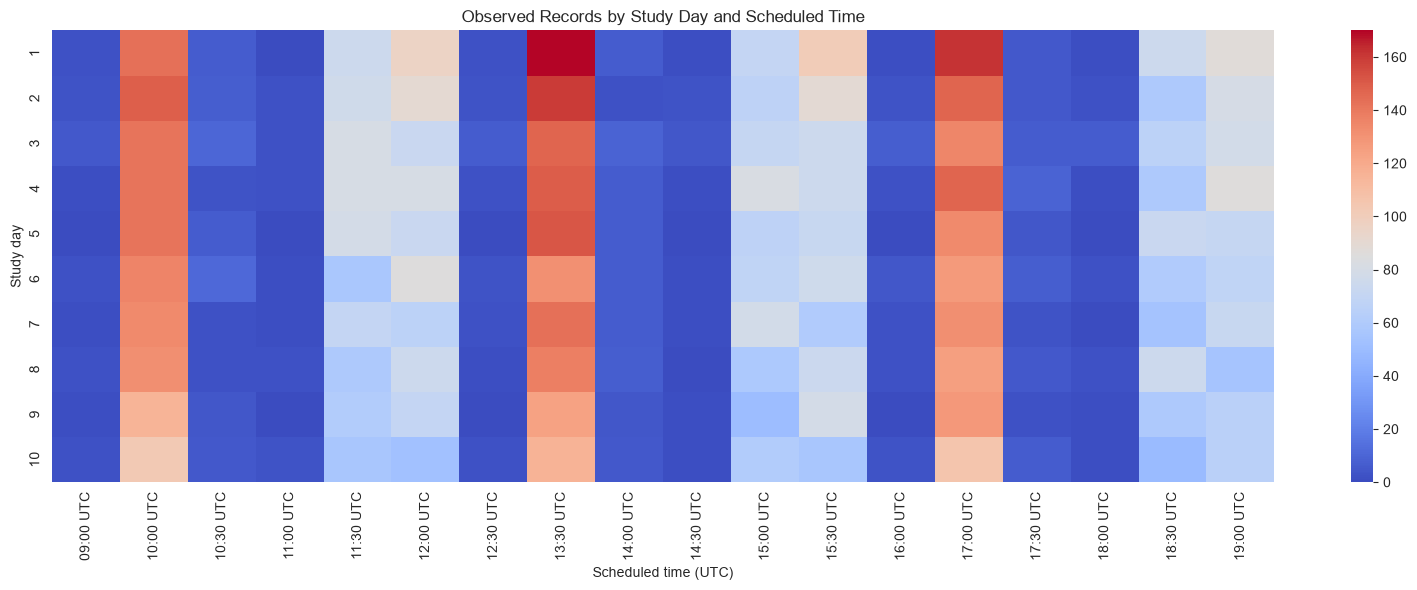

In [32]:
plot_df = df.copy()

plot_df["scheduled"] = pd.to_datetime(
    plot_df["scheduled"],
    errors="coerce",
    utc=True
)

# Extract UTC time of day
plot_df["utc_minutes"] = (
    plot_df["scheduled"].dt.hour * 60
    + plot_df["scheduled"].dt.minute
)

# Group into 30-minute intervals
plot_df["time_bin"] = (
    (plot_df["utc_minutes"] // 30) * 30
)

heatmap_data = plot_df.pivot_table(
    index="day",
    columns="time_bin",
    values="id",
    aggfunc="count",
    fill_value=0
)

heatmap_data.columns = [
    f"{int(m // 60):02d}:{int(m % 60):02d} UTC"
    for m in heatmap_data.columns
]

plt.figure(figsize=(16, 6))
sns.heatmap(heatmap_data, cmap="coolwarm")
plt.title("Observed Records by Study Day and Scheduled Time")
plt.xlabel("Scheduled time (UTC)")
plt.ylabel("Study day")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [33]:
print("Earliest scheduled timestamp:")
print(plot_df["scheduled"].min())

print("\nLatest scheduled timestamp:")
print(plot_df["scheduled"].max())

print("\nNumber of records by UTC hour:")
print(
    plot_df["scheduled"]
    .dt.hour
    .value_counts()
    .sort_index()
)

Earliest scheduled timestamp:
2023-07-28 10:05:00+00:00

Latest scheduled timestamp:
2024-01-21 18:59:00+00:00

Number of records by UTC hour:
scheduled
9       19
10    1394
11     709
12     783
13    1431
14      70
15    1429
16      24
17    1395
18     645
19     727
Name: count, dtype: int64


In [34]:
participant_hours = (
    plot_df.dropna(subset=["scheduled"])
    .assign(
        hour=lambda x: x["scheduled"].dt.hour
    )
    .groupby("id")["hour"]
    .agg(["min", "max", "count"])
)

print(participant_hours.describe())
print(participant_hours.head(20))

              min         max      count
count  227.000000  227.000000  227.00000
mean    10.066079   18.634361   38.00000
std      0.968552    1.227725   16.12479
min      9.000000   11.000000    1.00000
25%     10.000000   19.000000   29.00000
50%     10.000000   19.000000   42.00000
75%     10.000000   19.000000   51.00000
max     19.000000   19.000000   59.00000
            min  max  count
id                         
s003987858   10   19     55
s007948742   10   19     16
s011218896   10   19     53
s016682323   10   19     37
s019142072   10   19     53
s020463218   10   19     58
s022982490   10   19     36
s023074519   10   18     17
s043743192   10   19     34
s053344991   10   19     12
s056881262   10   19     54
s058105156   10   18     18
s064082249   10   18      4
s066708509   10   19     48
s067831619   10   19     39
s083391488   10   19     55
s093180153    9   19     52
s101673570   10   19     24
s106397307   10   19     46
s111482875   10   19     49


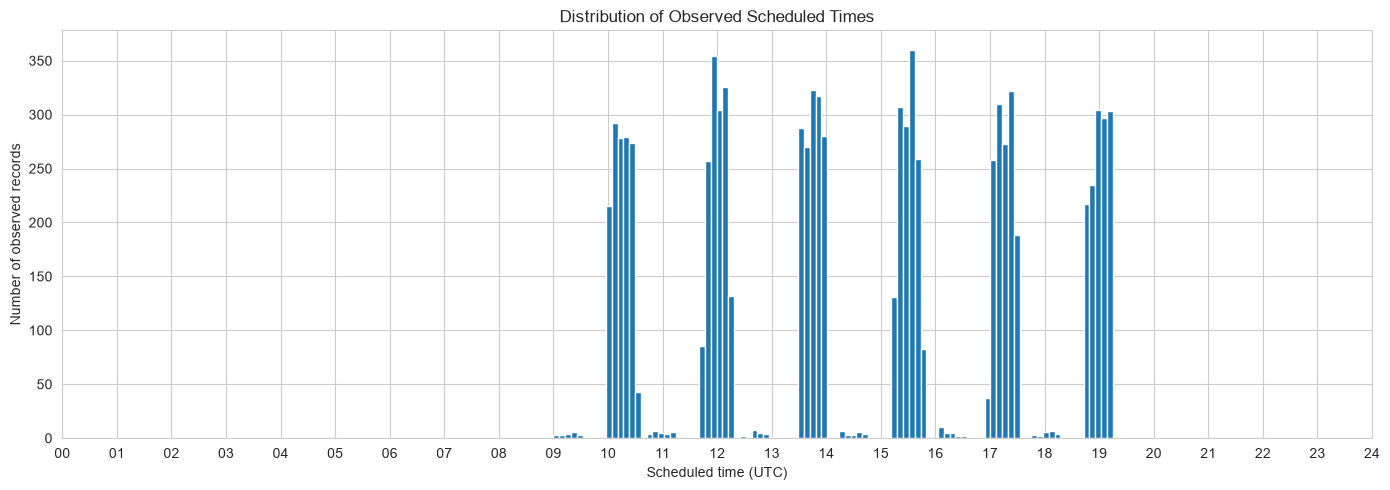

In [35]:
plot_df = df.copy()

plot_df["scheduled"] = pd.to_datetime(
    plot_df["scheduled"],
    errors="coerce",
    utc=True
)

plot_df["minute_of_day"] = (
    plot_df["scheduled"].dt.hour * 60
    + plot_df["scheduled"].dt.minute
)

plt.figure(figsize=(14, 5))

plt.hist(
    plot_df["minute_of_day"].dropna(),
    bins=96  # 15-minute bins across 24 hours
)

plt.xticks(
    range(0, 1441, 60),
    [f"{h:02d}" for h in range(25)],
    rotation=0
)

plt.xlabel("Scheduled time (UTC)")
plt.ylabel("Number of observed records")
plt.title("Distribution of Observed Scheduled Times")
plt.tight_layout()
plt.show()

In [36]:
df["participant_timezone"].unique()

<ArrowStringArray>
[    'Europe/Berlin',  'Europe/Amsterdam',             'local',
 'Europe/Luxembourg',     'Europe/Vienna',       'Europe/Rome',
 'Europe/Copenhagen',     'Europe/Prague',     'Europe/Zurich',
     'Europe/Warsaw',      'Europe/Paris',     'Europe/Zagreb',
   'Europe/Belgrade',  'Europe/Podgorica']
Length: 14, dtype: str

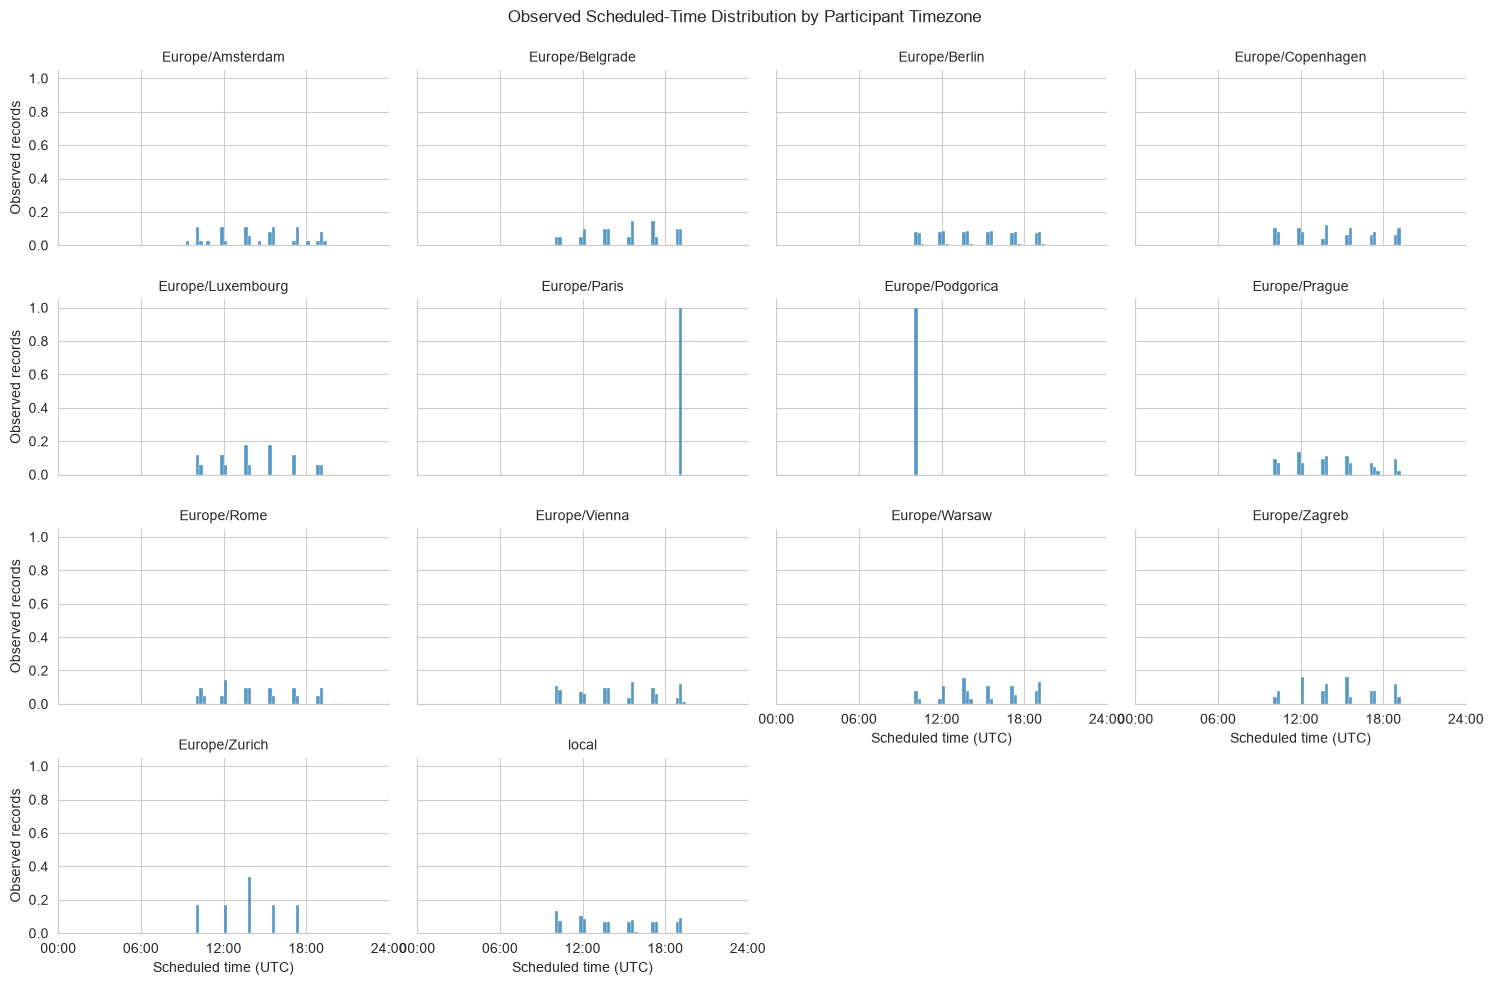

In [37]:
timezone_order = sorted(
    plot_df["participant_timezone"].unique()
)

g = sns.FacetGrid(
    plot_df,
    col="participant_timezone",
    col_order=timezone_order,
    col_wrap=4,
    sharex=True,
    sharey=True,
    height=2.5,
    aspect=1.5
)

g.map_dataframe(
    sns.histplot,
    x="minute_of_day",
    bins=96,
    binrange=(0, 1440),
    stat="probability",
    common_norm=False
)

g.set_titles("{col_name}")
g.set_axis_labels("Scheduled time (UTC)", "Observed records")

for ax in g.axes.flat:
    ax.set_xlim(0, 1440)
    ax.set_xticks(range(0, 1441, 360))
    ax.set_xticklabels(
        ["00:00", "06:00", "12:00", "18:00", "24:00"]
    )

g.figure.subplots_adjust(top=0.92)
g.figure.suptitle(
    "Observed Scheduled-Time Distribution by Participant Timezone"
)

plt.show()

In [38]:
print(
    plot_df.groupby("participant_timezone")
    .agg(
        records=("id", "size"),
        unique_participants=("id", "nunique"),
        unique_times=("minute_of_day", "nunique")
    )
    .sort_values("records")
)

                      records  unique_participants  unique_times
participant_timezone                                            
Europe/Podgorica            1                    1             1
Europe/Paris                1                    1             1
Europe/Zurich               6                    2             6
Europe/Luxembourg          17                    1            17
Europe/Rome                21                    2            20
Europe/Belgrade            21                    1            20
Europe/Zagreb              25                    1            25
Europe/Amsterdam           37                    3            35
Europe/Warsaw              38                    1            37
Europe/Prague              44                    3            41
Europe/Copenhagen          49                    2            43
Europe/Vienna              84                   11            71
local                     172                    7           111
Europe/Berlin            

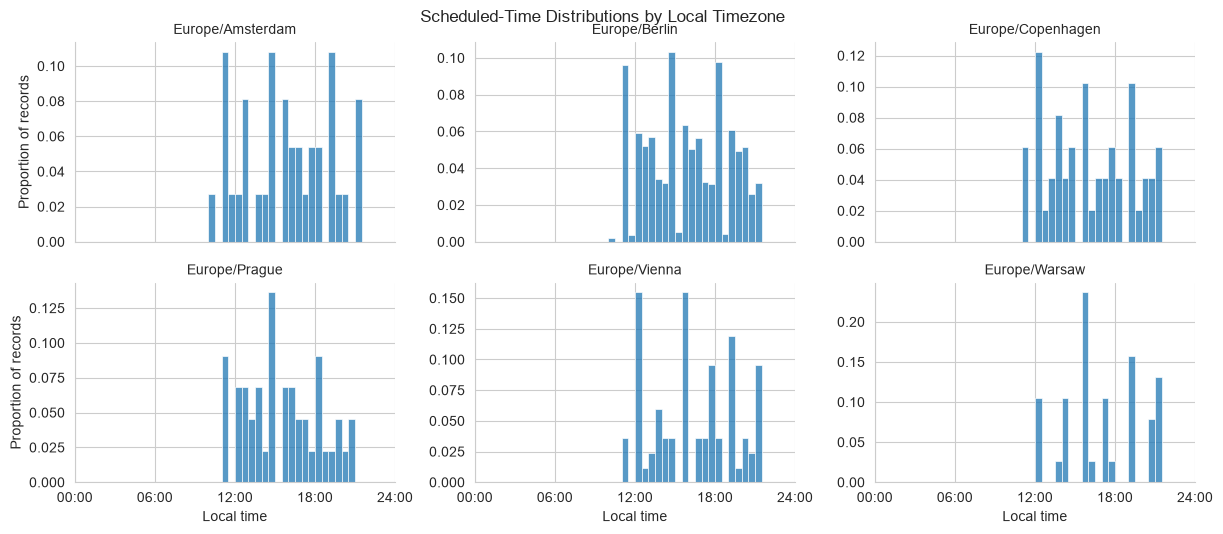

In [39]:
local_df = df.copy()

local_df["scheduled"] = pd.to_datetime(
    local_df["scheduled"], errors="coerce", utc=True
)

local_df["local_minute"] = float("nan")

valid_timezones = (
    local_df["participant_timezone"].dropna().unique()
)

for tz in valid_timezones:
    if tz == "local":
        continue

    mask = local_df["participant_timezone"].eq(tz)
    local_time = local_df.loc[mask, "scheduled"].dt.tz_convert(tz)

    local_df.loc[mask, "local_minute"] = (
        local_time.dt.hour * 60 + local_time.dt.minute
    )

local_df["local_minute"] = local_df["local_minute"].astype("float")

local_df["time_bin"] = (
    local_df["local_minute"] // 15 * 15
)

# Focus on groups with enough records to interpret
counts = local_df["participant_timezone"].value_counts()
major_groups = counts[counts >= 30].index

facet_df = local_df[
    local_df["participant_timezone"].isin(major_groups)
    & local_df["local_minute"].notna()
].copy()

g = sns.FacetGrid(
    facet_df,
    col="participant_timezone",
    col_order=sorted(facet_df["participant_timezone"].unique()),
    col_wrap=3,
    sharex=True,
    sharey=False,
    height=2.7,
    aspect=1.5
)

g.map_dataframe(
    sns.histplot,
    x="local_minute",
    bins=48,
    binrange=(0, 1440),
    stat="probability",
    common_norm=False
)

g.set_titles("{col_name}")
g.set_axis_labels("Local time", "Proportion of records")

for ax in g.axes.flat:
    ax.set_xlim(0, 1440)
    ax.set_xticks([0, 360, 720, 1080, 1440])
    ax.set_xticklabels(["00:00", "06:00", "12:00", "18:00", "24:00"])

g.figure.subplots_adjust(top=0.92)
g.figure.suptitle("Scheduled-Time Distributions by Local Timezone")
plt.show()

In [40]:
response_counts = model_df.groupby("id")["responded"].sum()
participants_to_drop = response_counts[response_counts == 1].index
model_df = model_df[~model_df["id"].isin(participants_to_drop)].copy()

In [41]:
model_df.tail(40)

,id,day,beep,date,participant_timezone,export_timezone,created,scheduled,started,completed,expired,uploaded,guilty_emotion,out_of_control,embarrassed_emotion,negative_self_thoughts,emotion_confusion,ashamed_emotion,task_difficulty,prolonged_emotion_expectation,annoyed_at_self,behavior_control_difficulty,confused_emotions,down_expectation,emotions_out_of_control,annoyed_at_self_emotion,weak_emotion,overwhelming_emotions,affect_grid_x,affect_grid_y,seek_contact_affect,others_perspective_giving,received_comfort,received_coping_examples,negative_event,positive_event,impulse_contact_emotion_regulation,impulse_self_regulation,quest_duration,time,emotion_awareness,acknowledge_emotions,care_about_emotions,emotion_exploration,emotions_valid,time_minutes,time_to_complete,time_to_complete_minutes,responded
13580,s985659374,4,3,2024-01-14,Europe/Berlin,Europe/Berlin,2024-01-14 16:03:00+00:00,2024-01-14 15:33:00+00:00,2024-01-14 16:03:00+00:00,2024-01-14 16:04:00+00:00,NaN,2024-01-14 16:04:00+00:00,1.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,4.0,3.0,3.0,3.0,3.0,4.0,4.0,5.0,2.0,6.0,60.0,16:04:00,2.0,1.0,1.0,2.0,1.0,964.0,60.0,1.0,1
13581,s985659374,4,4,2024-01-14,Europe/Berlin,Europe/Berlin,2024-01-14 17:30:00+00:00,2024-01-14 17:02:00+00:00,2024-01-14 17:30:00+00:00,2024-01-14 17:31:00+00:00,NaN,2024-01-14 17:31:00+00:00,1.0,1.0,1.0,1.0,1.0,1.0,3.0,2.0,1.0,1.0,2.0,1.0,1.0,1.0,3.0,1.0,5.0,2.0,3.0,2.0,2.0,2.0,3.0,5.0,3.0,6.0,60.0,17:31:00,2.0,1.0,1.0,2.0,1.0,1051.0,60.0,1.0,1
13582,s985659374,4,5,2024-01-14,Europe/Berlin,Europe/Berlin,2024-01-14 19:40:00+00:00,2024-01-14 19:01:00+00:00,2024-01-14 19:40:00+00:00,2024-01-14 19:41:00+00:00,NaN,2024-01-14 19:41:00+00:00,1.0,1.0,1.0,1.0,2.0,1.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,4.0,1.0,2.0,3.0,2.0,3.0,5.0,3.0,1.0,6.0,60.0,19:41:00,1.0,1.0,1.0,2.0,1.0,1181.0,60.0,1.0,1
13583,s985659374,4,6,NaT,NaN,NaN,NaT,NaT,NaT,NaT,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
13584,s985659374,5,1,2024-01-15,Europe/Berlin,Europe/Berlin,2024-01-15 10:32:00+00:00,2024-01-15 10:06:00+00:00,2024-01-15 10:32:00+00:00,2024-01-15 10:33:00+00:00,NaN,2024-01-15 10:33:00+00:00,1.0,1.0,1.0,1.0,1.0,1.0,4.0,1.0,1.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,4.0,2.0,1.0,2.0,1.0,2.0,5.0,2.0,1.0,6.0,60.0,10:33:00,3.0,2.0,1.0,5.0,1.0,633.0,60.0,1.0,1
13585,s985659374,5,2,2024-01-15,Europe/Berlin,Europe/Berlin,2024-01-15 12:08:00+00:00,2024-01-15 12:08:00+00:00,2024-01-15 12:08:00+00:00,2024-01-15 12:09:00+00:00,NaN,2024-01-15 12:09:00+00:00,1.0,1.0,1.0,1.0,3.0,1.0,4.0,1.0,1.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,5.0,2.0,2.0,3.0,2.0,2.0,4.0,5.0,2.0,6.0,60.0,12:09:00,2.0,2.0,1.0,2.0,1.0,729.0,60.0,1.0,1
13586,s985659374,5,3,2024-01-15,Europe/Berlin,Europe/Berlin,2024-01-15 13:37:00+00:00,2024-01-15 13:35:00+00:00,2024-01-15 13:37:00+00:00,2024-01-15 13:37:00+00:00,NaN,2024-01-15 13:37:00+00:00,1.0,2.0,1.0,1.0,2.0,1.0,3.0,1.0,1.0,2.0,1.0,2.0,1.0,1.0,1.0,3.0,7.0,1.0,3.0,2.0,2.0,2.0,5.0,3.0,2.0,6.0,0.0,13:37:00,5.0,1.0,1.0,2.0,1.0,817.0,0.0,0.0,1
13587,s985659374,5,4,NaT,NaN,NaN,NaT,NaT,NaT,NaT,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
13588,s985659374,5,5,NaT,NaN,NaN,NaT,NaT,NaT,NaT,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
13589,s985659374,5,6,NaT,NaN,NaN,NaT,NaT,NaT,NaT,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


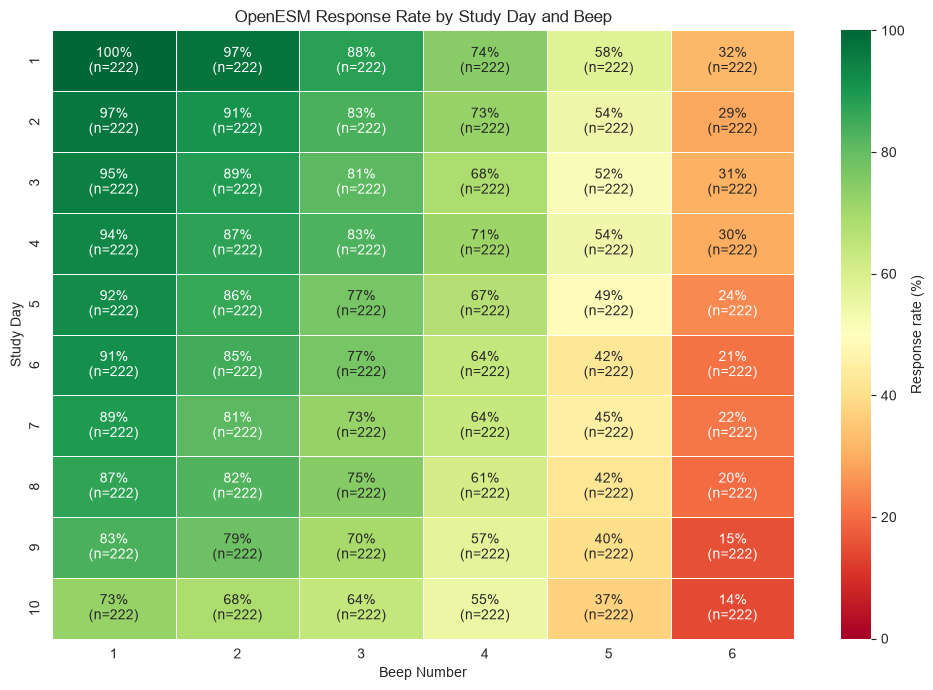

In [42]:
summary = (
    model_df
    .groupby(["day", "beep"])["responded"]
    .agg(response_rate="mean", n="count", responses="sum")
    .reset_index()
)

# Matrices for plotting
rate_matrix = summary.pivot(
    index="day", columns="beep", values="response_rate"
)
count_matrix = summary.pivot(
    index="day", columns="beep", values="n"
)

annotations = rate_matrix.copy().astype(object)

for day in rate_matrix.index:
    for beep in rate_matrix.columns:
        rate = rate_matrix.loc[day, beep]
        n = count_matrix.loc[day, beep]

        annotations.loc[day, beep] = (
            f"{rate:.0%}\n(n={int(n)})"
            if pd.notna(rate) and pd.notna(n)
            else ""
        )

plt.figure(figsize=(10, 7))

sns.heatmap(
    rate_matrix * 100,
    annot=annotations,
    fmt="",
    cmap="RdYlGn",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Response rate (%)"}
)

plt.title("OpenESM Response Rate by Study Day and Beep")
plt.xlabel("Beep Number")
plt.ylabel("Study Day")
plt.tight_layout()
plt.show()

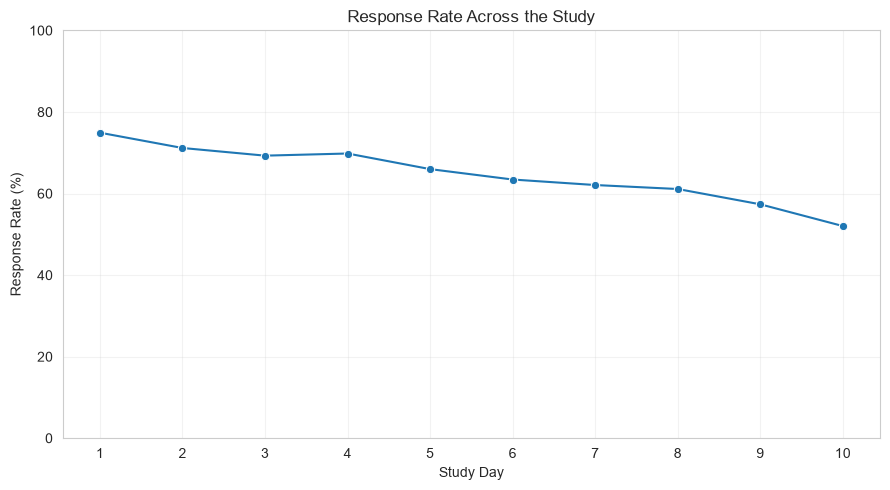

   day  responses  scheduled  response_rate_pct
0    1        998       1332               74.9
1    2        948       1332               71.2
2    3        923       1332               69.3
3    4        930       1332               69.8
4    5        879       1332               66.0
5    6        845       1332               63.4
6    7        827       1332               62.1
7    8        814       1332               61.1
8    9        764       1332               57.4
9   10        693       1332               52.0


In [43]:
daily = (
    model_df.groupby("day")["responded"]
    .agg(response_rate="mean", responses="sum", scheduled="count")
    .reset_index()
)

daily["response_rate_pct"] = daily["response_rate"] * 100

plt.figure(figsize=(9, 5))
sns.lineplot(
    data=daily,
    x="day",
    y="response_rate_pct",
    marker="o"
)
plt.xticks(range(1, 11))
plt.ylim(0, 100)
plt.xlabel("Study Day")
plt.ylabel("Response Rate (%)")
plt.title("Response Rate Across the Study")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(daily[["day", "responses", "scheduled", "response_rate_pct"]].round(1))

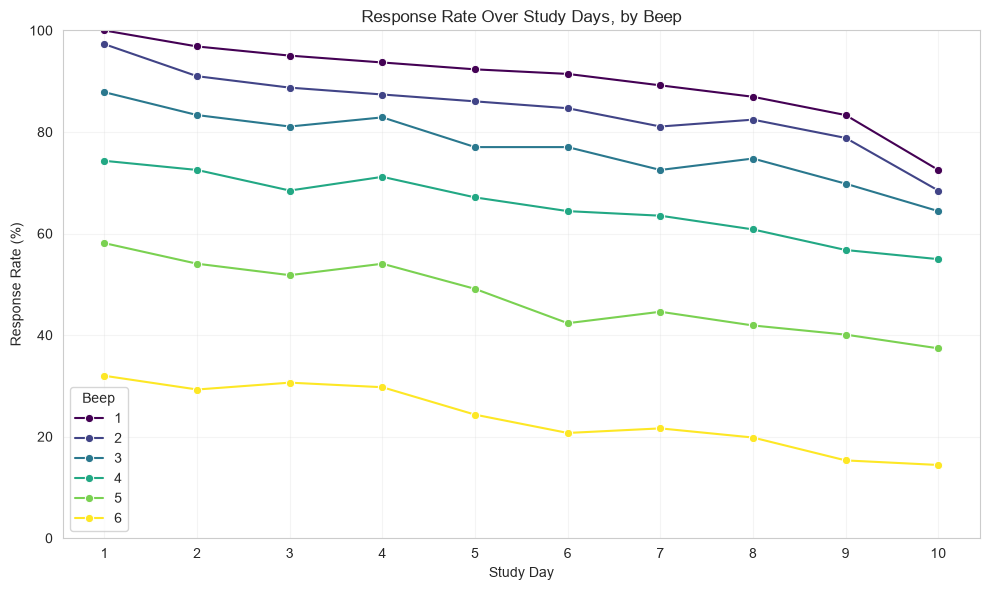

In [44]:
beep_daily = (
    model_df.groupby(["day", "beep"])["responded"]
    .mean()
    .mul(100)
    .reset_index(name="response_rate_pct")
)

plt.figure(figsize=(10, 6))
sns.lineplot(
    data=beep_daily,
    x="day",
    y="response_rate_pct",
    hue="beep",
    marker="o",
    palette="viridis"
)
plt.xticks(range(1, 11))
plt.ylim(0, 100)
plt.xlabel("Study Day")
plt.ylabel("Response Rate (%)")
plt.title("Response Rate Over Study Days, by Beep")
plt.legend(title="Beep")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [45]:
daily_participation = (
    model_df
    .groupby(["id", "day"])["responded"]
    .max()
    .reset_index(name="responded_any")
)

# Last study day with any response
last_response = (
    daily_participation[daily_participation["responded_any"] == 1]
    .groupby("id")["day"]
    .max()
    .rename("last_response_day")
)

# One row per participant
participant_status = (
    model_df[["id"]]
    .drop_duplicates()
    .set_index("id")
    .join(last_response)
    .reset_index()
)

# Flag participants who never responded
participant_status["never_responded"] = (
    participant_status["last_response_day"].isna()
)

# First day after their final observed response
participant_status["apparent_quit_day"] = (
    participant_status["last_response_day"] + 1
).where(participant_status["last_response_day"] < 10)

# Apparent dropout before the end of the 10-day study
participant_status["apparent_dropout"] = (
    participant_status["last_response_day"].notna()
    & (participant_status["last_response_day"] < 10)
)

print(participant_status.sort_values(
    ["apparent_dropout", "last_response_day"],
    ascending=[False, True],
    na_position="first"
).to_string(index=False))

        id  last_response_day  never_responded  apparent_quit_day  apparent_dropout
s064082249                  1            False                2.0              True
s188991456                  1            False                2.0              True
s328071033                  1            False                2.0              True
s603764415                  1            False                2.0              True
s603787905                  1            False                2.0              True
s746307800                  1            False                2.0              True
s808110080                  1            False                2.0              True
s053344991                  2            False                3.0              True
s284062525                  2            False                3.0              True
s567876360                  2            False                3.0              True
s757074006                  2            False                3.0           

In [46]:
model_df = model_df.merge(
    participant_status,
    on="id",
    how="left",
    validate="many_to_one"
)

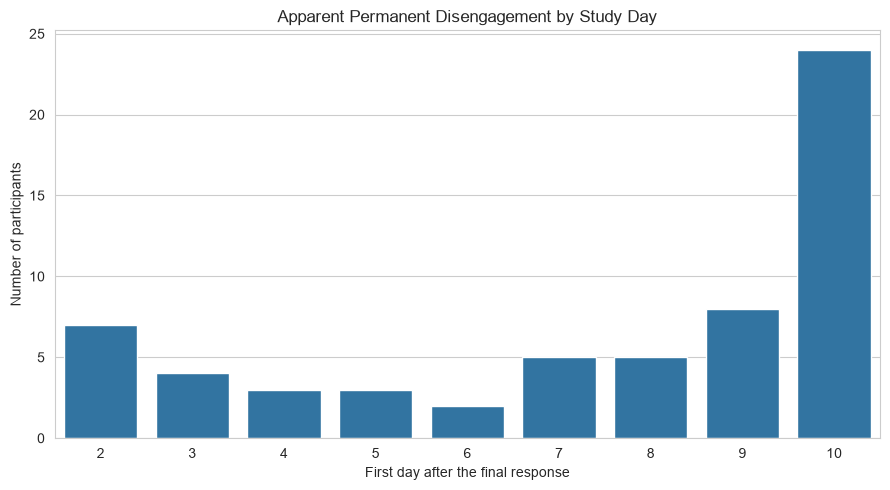

In [47]:
dropout_counts = (
    participant_status[
        participant_status["apparent_dropout"]
    ]
    .groupby("apparent_quit_day")
    .size()
    .reindex(range(2, 11), fill_value=0)
    .rename("participants")
    .reset_index()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=dropout_counts,
    x="apparent_quit_day",
    y="participants"
)

plt.xlabel("First day after the final response")
plt.ylabel("Number of participants")
plt.title("Apparent Permanent Disengagement by Study Day")
plt.tight_layout()
plt.show()

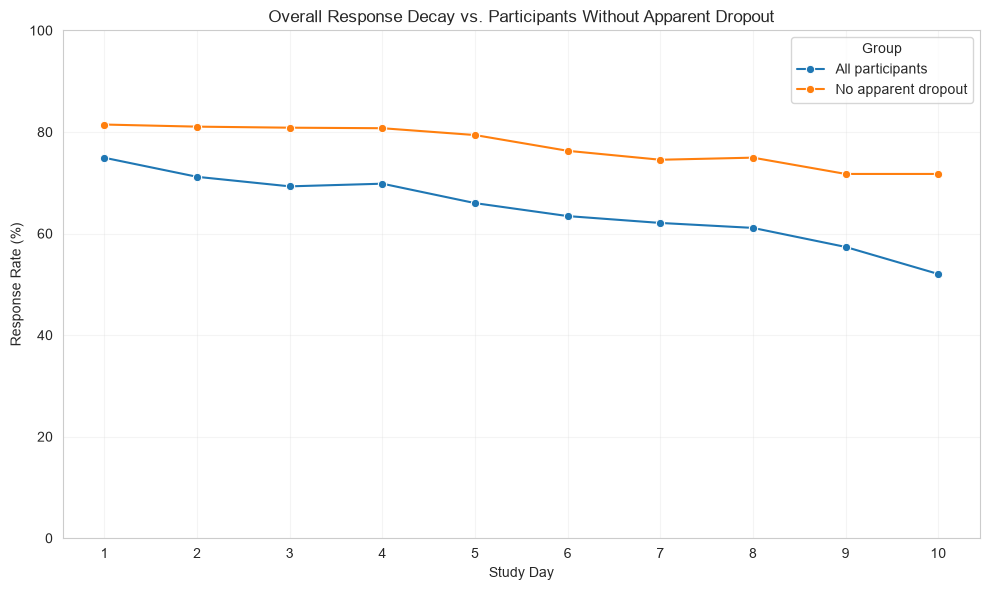

In [48]:
overall = (
    model_df.groupby("day")["responded"]
    .mean()
    .mul(100)
    .rename("All participants")
)

# Response rate among participants without apparent dropout
retained_ids = participant_status.loc[
    ~participant_status["apparent_dropout"]
    & ~participant_status["never_responded"],
    "id"
]

retained = (
    model_df[model_df["id"].isin(retained_ids)]
    .groupby("day")["responded"]
    .mean()
    .mul(100)
    .rename("No apparent dropout")
)

comparison = pd.concat([overall, retained], axis=1).reset_index()
comparison = comparison.melt(
    id_vars="day",
    var_name="Group",
    value_name="Response rate (%)"
)

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=comparison,
    x="day",
    y="Response rate (%)",
    hue="Group",
    marker="o"
)

plt.xticks(range(1, 11))
plt.ylim(0, 100)
plt.xlabel("Study Day")
plt.ylabel("Response Rate (%)")
plt.title("Overall Response Decay vs. Participants Without Apparent Dropout")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

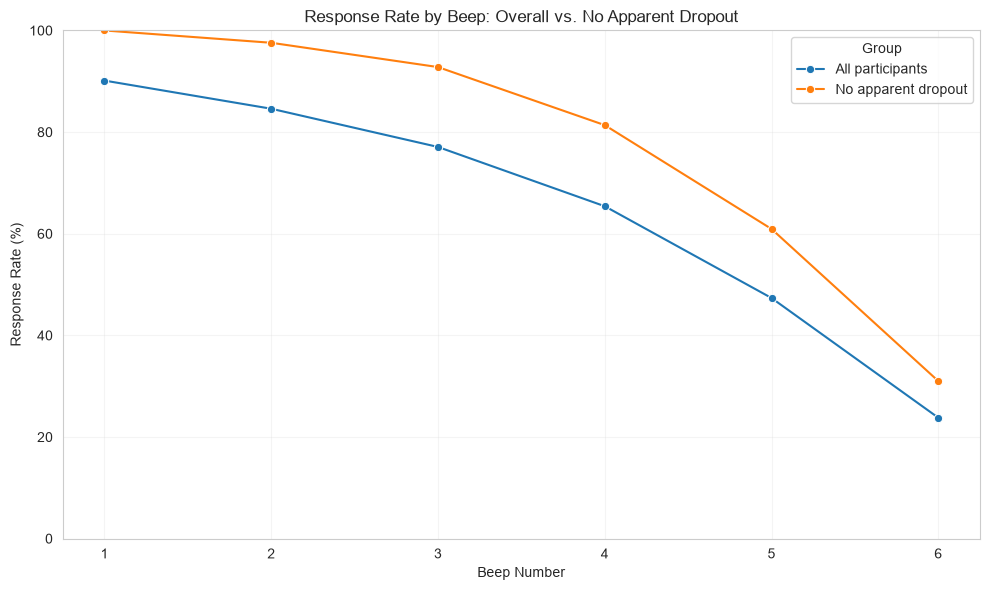

In [49]:
overall_beep = (
    model_df.groupby("beep")["responded"]
    .mean()
    .mul(100)
    .rename("All participants")
)

# Response rate among participants without apparent dropout
retained_beep = (
    model_df[model_df["id"].isin(retained_ids)]
    .groupby("beep")["responded"]
    .mean()
    .mul(100)
    .rename("No apparent dropout")
)

beep_comparison = (
    pd.concat([overall_beep, retained_beep], axis=1)
    .reset_index()
    .melt(
        id_vars="beep",
        var_name="Group",
        value_name="Response rate (%)"
    )
)

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=beep_comparison,
    x="beep",
    y="Response rate (%)",
    hue="Group",
    marker="o"
)

plt.xticks(sorted(model_df["beep"].unique()))
plt.ylim(0, 100)
plt.xlabel("Beep Number")
plt.ylabel("Response Rate (%)")
plt.title("Response Rate by Beep: Overall vs. No Apparent Dropout")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

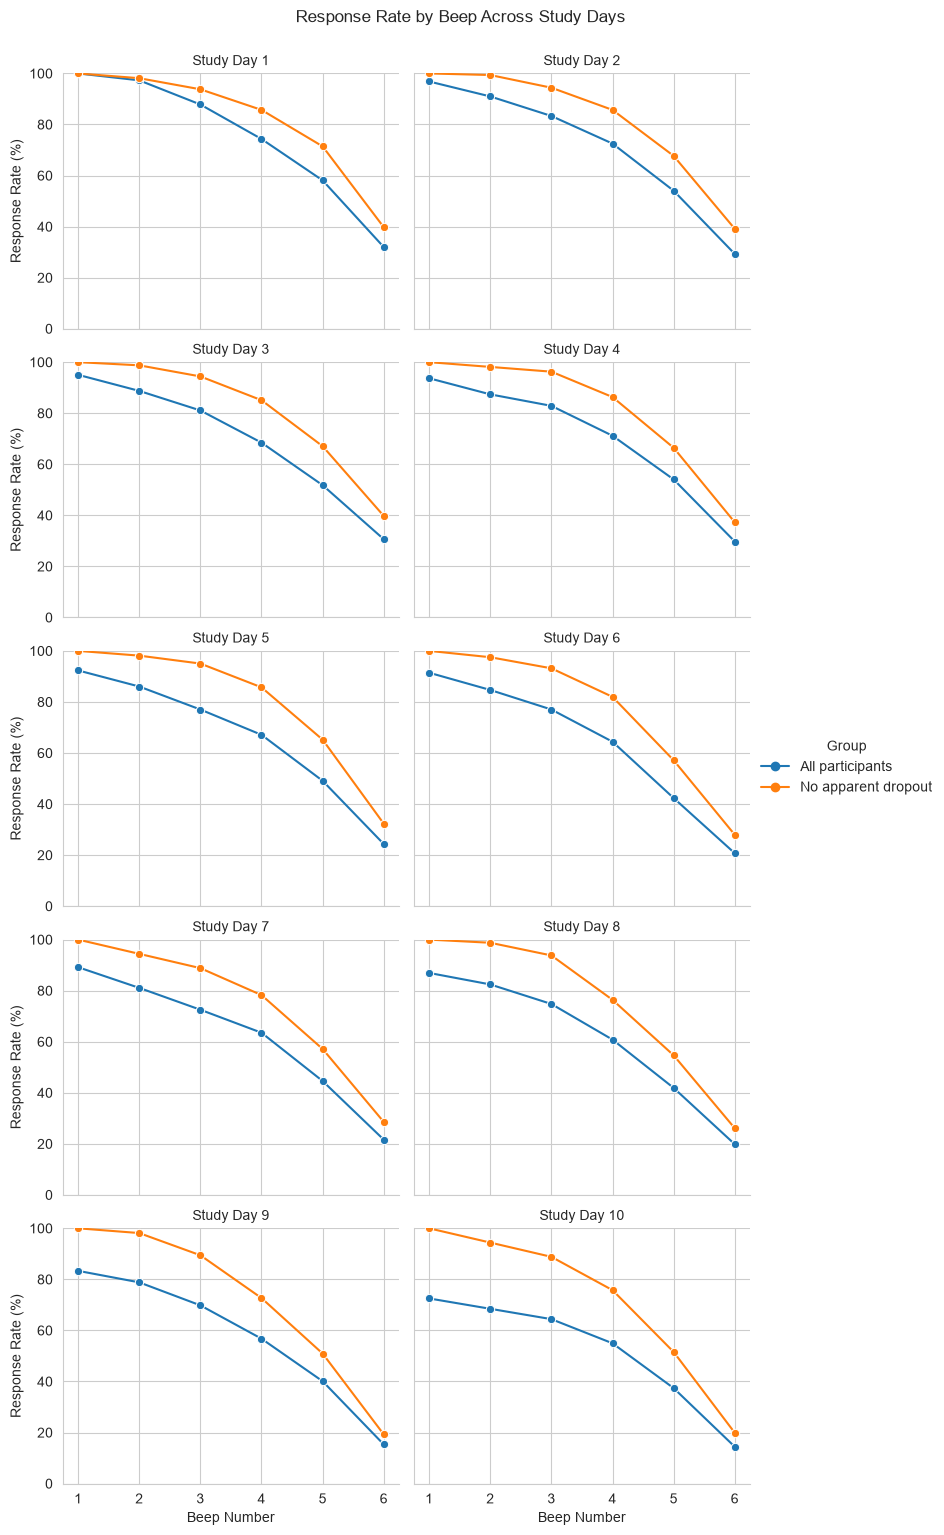

In [50]:
overall_day_beep = (
    model_df.groupby(["day", "beep"])["responded"]
    .mean()
    .mul(100)
    .rename("All participants")
)

retained_day_beep = (
    model_df[model_df["id"].isin(retained_ids)]
    .groupby(["day", "beep"])["responded"]
    .mean()
    .mul(100)
    .rename("No apparent dropout")
)

day_beep_comparison = (
    pd.concat([overall_day_beep, retained_day_beep], axis=1)
    .reset_index()
    .melt(
        id_vars=["day", "beep"],
        var_name="Group",
        value_name="Response rate (%)"
    )
)

g = sns.relplot(
    data=day_beep_comparison,
    x="beep",
    y="Response rate (%)",
    hue="Group",
    col="day",
    col_wrap=2,
    kind="line",
    marker="o",
    height=3,
    aspect=1.3,
    facet_kws={"sharey": True}
)

g.set_axis_labels("Beep Number", "Response Rate (%)")
g.set(xticks=sorted(model_df["beep"].unique()), ylim=(0, 100))
g.set_titles("Study Day {col_name}")
g.fig.suptitle(
    "Response Rate by Beep Across Study Days",
    y=1.02
)
plt.show()

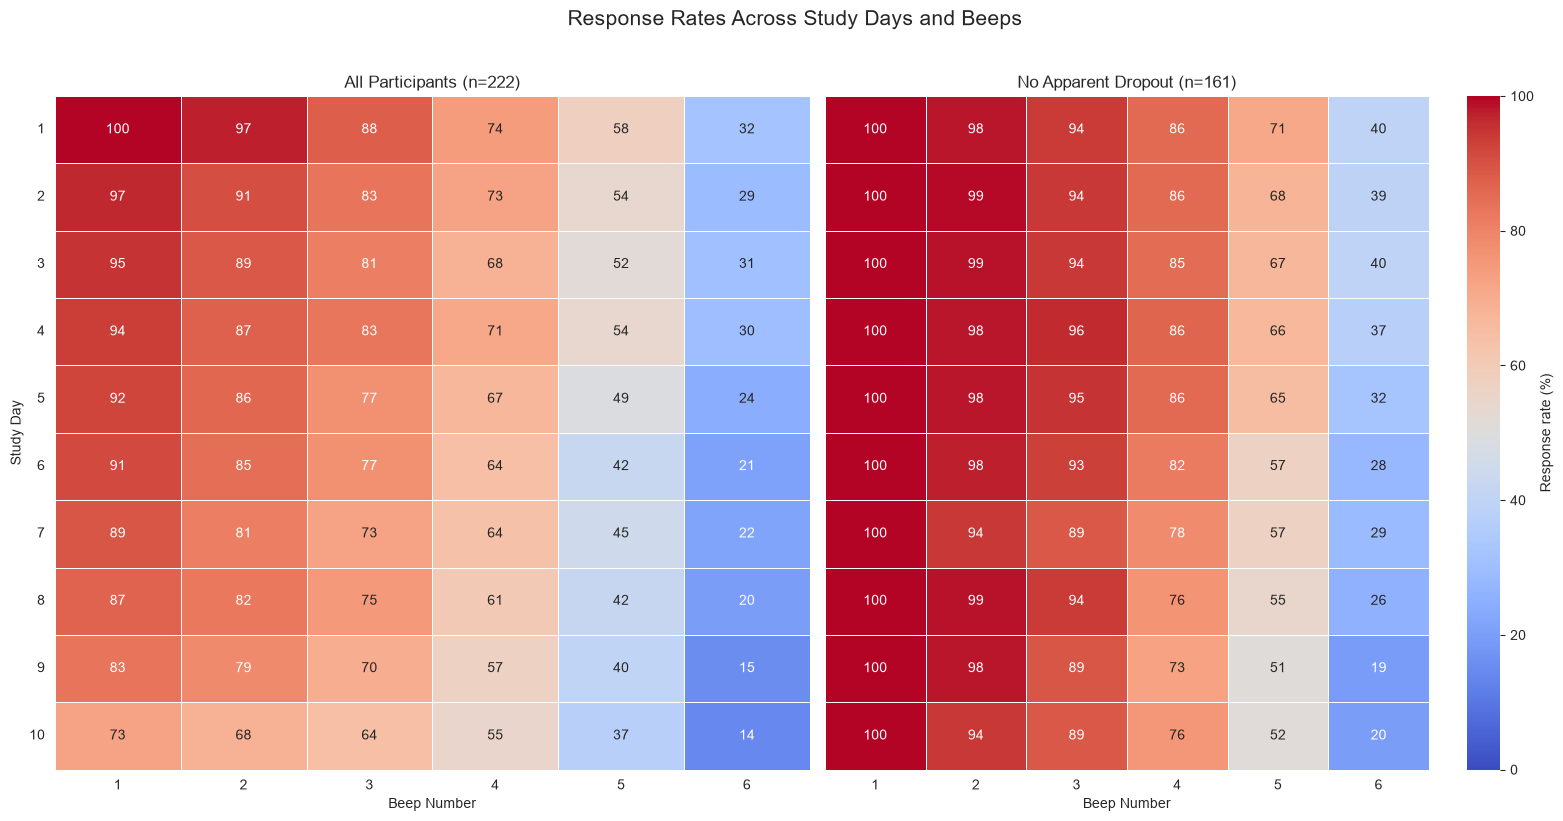

In [51]:
retained_df = model_df[model_df["id"].isin(retained_ids)]

# Calculate response rates for day × beep
overall_rates = (
    model_df.groupby(["day", "beep"])["responded"]
    .mean()
    .mul(100)
    .unstack("beep")
    .reindex(index=range(1, 11), columns=range(1, 7))
)

retained_rates = (
    retained_df.groupby(["day", "beep"])["responded"]
    .mean()
    .mul(100)
    .unstack("beep")
    .reindex(index=range(1, 11), columns=range(1, 7))
)

# Plot side by side, using the same color scale
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharey=True)

sns.heatmap(
    overall_rates,
    ax=axes[0],
    annot=True,
    fmt=".0f",
    cmap="coolwarm",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar=False
)

sns.heatmap(
    retained_rates,
    ax=axes[1],
    annot=True,
    fmt=".0f",
    cmap="coolwarm",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar=True,
    cbar_kws={"label": "Response rate (%)"}
)

axes[0].set_title(
    f"All Participants (n={model_df['id'].nunique()})"
)
axes[1].set_title(
    f"No Apparent Dropout (n={retained_df['id'].nunique()})"
)

for ax in axes:
    ax.set_xlabel("Beep Number")
    ax.set_xticklabels(range(1, 7))
    ax.set_yticklabels(range(1, 11), rotation=0)

axes[0].set_ylabel("Study Day")
axes[1].set_ylabel("")

fig.suptitle(
    "Response Rates Across Study Days and Beeps",
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()

In [52]:
model_df = model_df.sort_values(
    ["id", "day", "beep"]
).copy()

# Cumulative number of responded-to prompts per participant
model_df["cumulative_responses"] = (
    model_df.groupby("id")["responded"].cumsum()
)

# Cumulative number of scheduled prompts per participant
model_df["cumulative_prompts"] = (
    model_df.groupby("id").cumcount() + 1
)

# Cumulative response rate (%) through this prompt
model_df["cumulative_response_rate"] = (
    model_df["cumulative_responses"]
    / model_df["cumulative_prompts"]
    * 100
)

# Did the participant respond to ANY beep that day?
daily_response = (
    model_df.groupby(["id", "day"])["responded"]
    .transform("max")
)

# Flag all prompts belonging to a day with zero responses
model_df["missed_day"] = (daily_response == 0).astype(int)

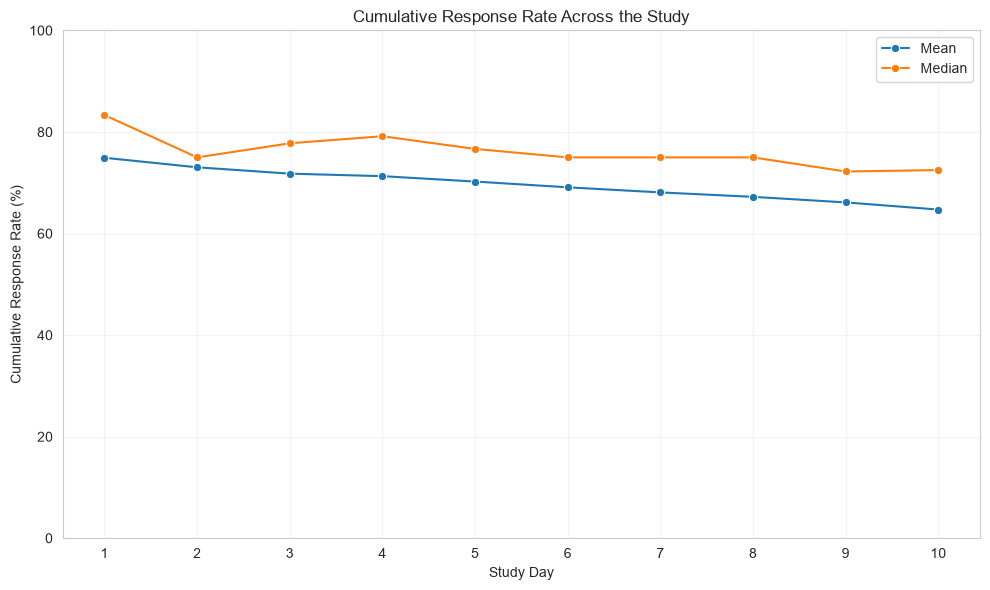

In [53]:
## Average cumulative response rate over study days

daily_cumulative = (
    model_df.groupby(["id", "day"])
    .agg(
        cumulative_response_rate=("cumulative_response_rate", "last")
    )
    .reset_index()
)

summary = (
    daily_cumulative.groupby("day")["cumulative_response_rate"]
    .agg(["mean", "median"])
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=summary,
    x="day",
    y="mean",
    marker="o",
    label="Mean"
)

sns.lineplot(
    data=summary,
    x="day",
    y="median",
    marker="o",
    label="Median"
)

plt.xticks(range(1, 11))
plt.ylim(0, 100)
plt.xlabel("Study Day")
plt.ylabel("Cumulative Response Rate (%)")
plt.title("Cumulative Response Rate Across the Study")
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

In [54]:
# print("Rows in heatmap:", cumulative_matrix.shape[0])
# print("Participants with any data:", cumulative_matrix.notna().any(axis=1).sum())
# print("Participants with final-day data:", cumulative_matrix[10].notna().sum())

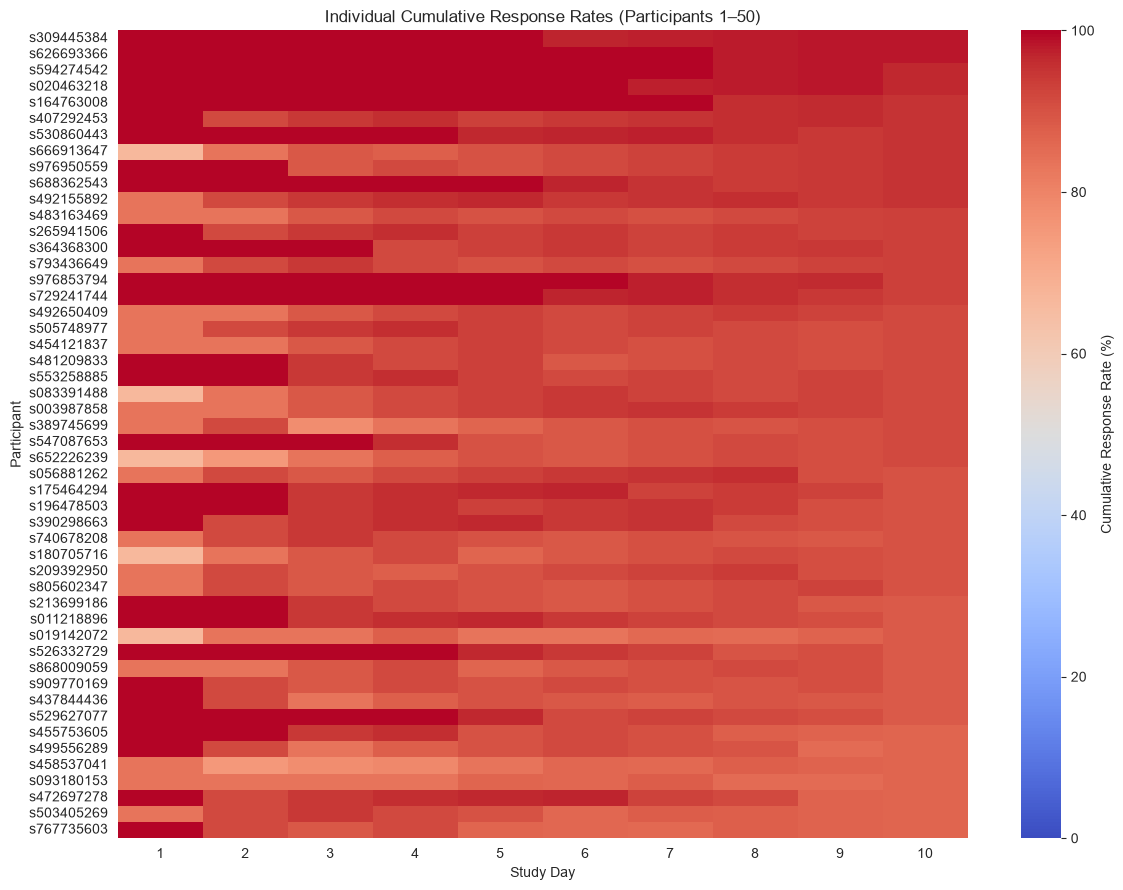

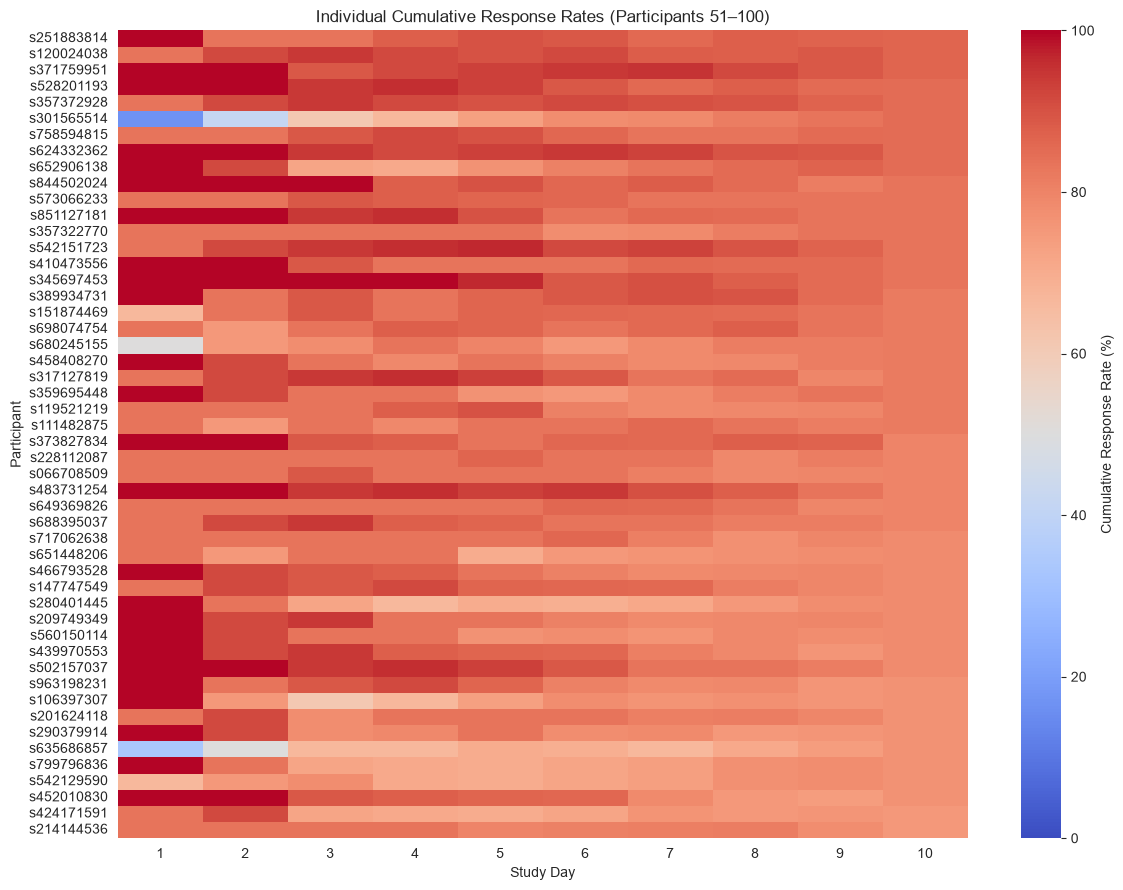

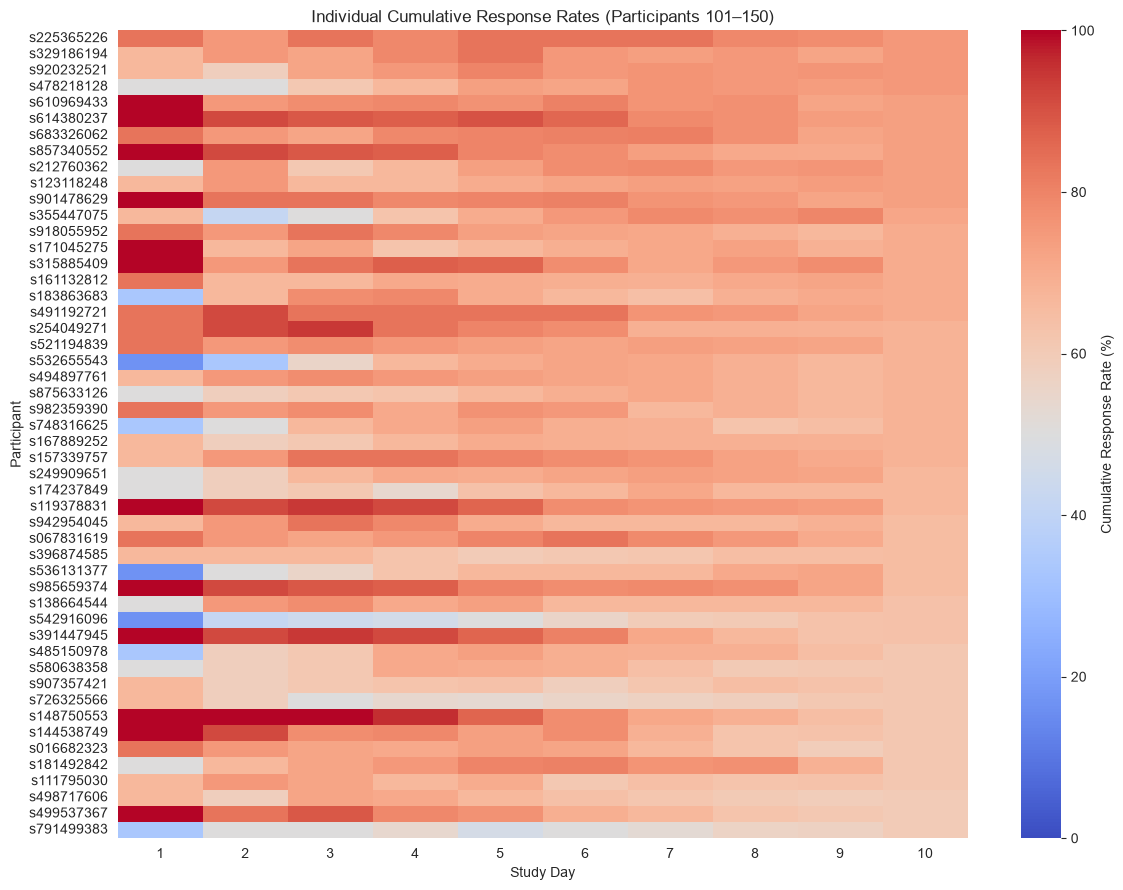

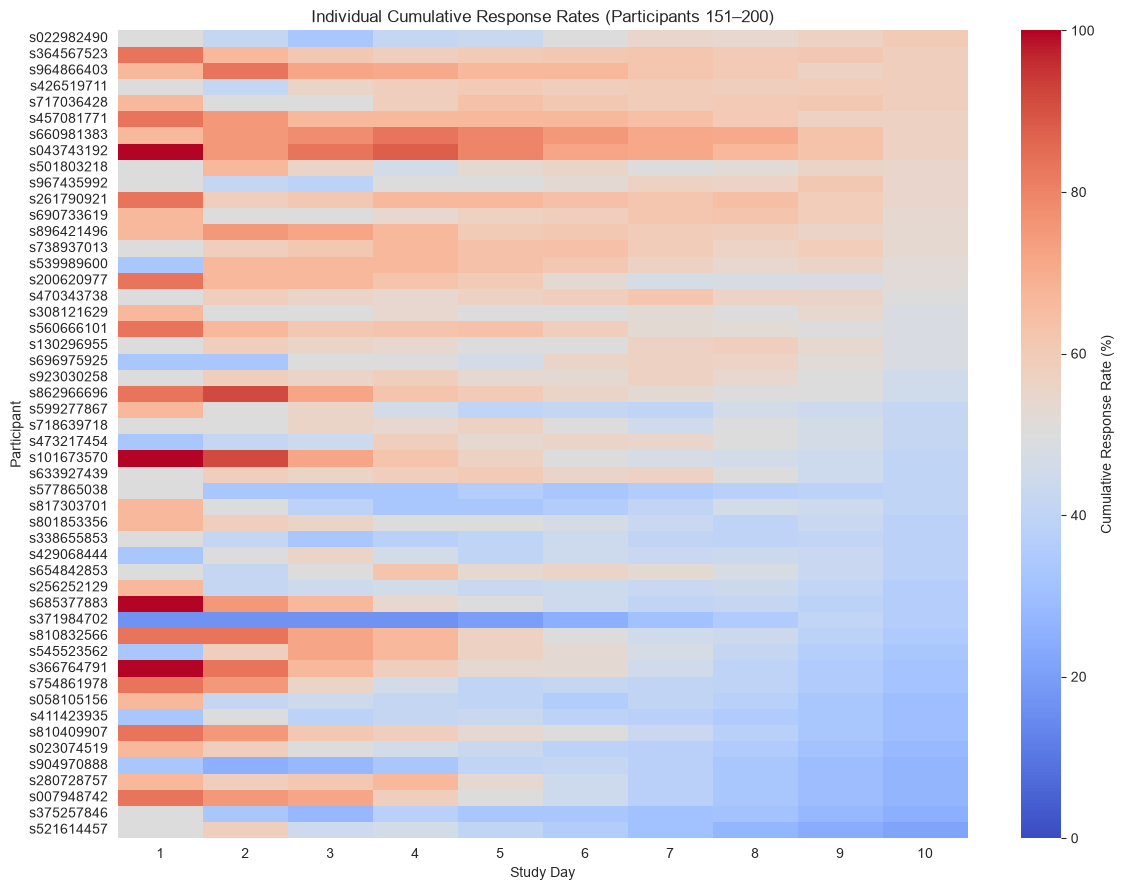

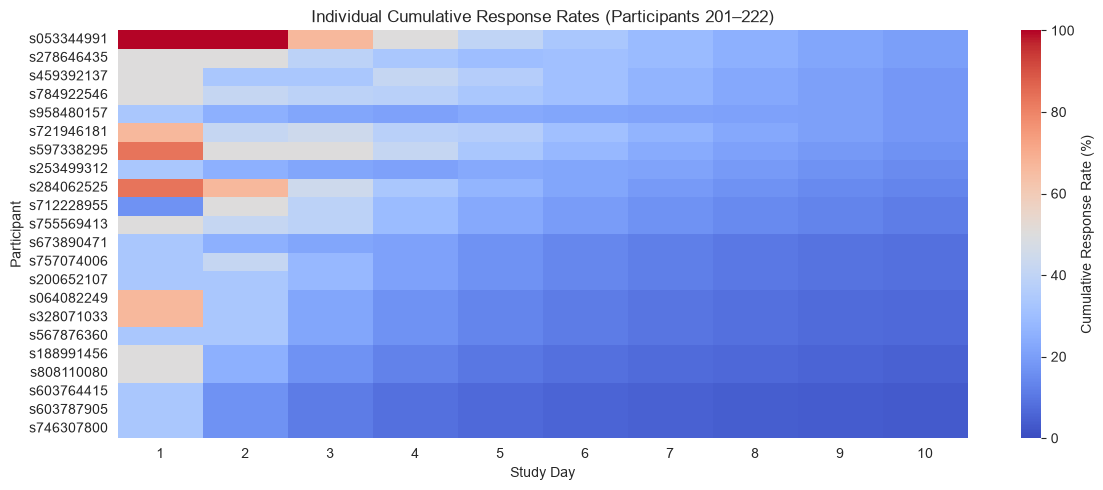

In [55]:
## Participant-level cumulative response heatmap, 50 participants at a time

cumulative_matrix = daily_cumulative.pivot(
    index="id",
    columns="day",
    values="cumulative_response_rate"
)

# Sort participants by their cumulative response rate on the final day
sort_order = cumulative_matrix[10].sort_values(
    ascending=False,
    na_position="last"
).index

cumulative_matrix = cumulative_matrix.loc[sort_order]

participants_per_plot = 50

for start in range(0, len(cumulative_matrix), participants_per_plot):
    subset = cumulative_matrix.iloc[start:start + participants_per_plot]

    plt.figure(figsize=(12, max(5, len(subset) * 0.18)))

    sns.heatmap(
        subset,
        cmap="coolwarm",
        vmin=0,
        vmax=100,
        cbar_kws={"label": "Cumulative Response Rate (%)"},
        yticklabels=True
    )

    plt.xlabel("Study Day")
    plt.ylabel("Participant")
    plt.title(
        f"Individual Cumulative Response Rates "
        f"(Participants {start + 1}–{start + len(subset)})"
    )
    plt.xticks(
        [i + 0.5 for i in range(10)],
        range(1, 11)
    )
    plt.tight_layout()
    plt.show()

In [56]:
from pathlib import Path
import pandas as pd

# Keep only modeling variables and the existing outcome
model_df = model_df[
    ["id", "day", "beep", "responded"]
].copy()

# Standardize the outcome name for the HMM code
model_df = model_df.rename(columns={"responded": "response"})

# Set data types
model_df["id"] = model_df["id"].astype(str)
model_df["day"] = model_df["day"].astype(int)
model_df["beep"] = model_df["beep"].astype(int)
model_df["response"] = model_df["response"].astype(int)

# Sort prompts chronologically within each participant
model_df = (
    model_df
    .sort_values(["id", "day", "beep"])
    .reset_index(drop=True)
)

# Group sequences
participant = model_df.groupby("id", sort=False)["response"]
participant_day = model_df.groupby(
    ["id", "day"], sort=False
)["response"]

# Causal response-history features
model_df["prev_response"] = participant.shift(1)

model_df["prev_response_same_day"] = (
    participant_day.shift(1)
)

model_df["prior_cumulative_response_rate"] = participant.transform(
    lambda s: s.shift(1).expanding(min_periods=1).mean()
)

model_df["prior_3_prompt_response_rate"] = participant.transform(
    lambda s: s.shift(1).rolling(3, min_periods=1).mean()
)

model_df["prior_day_response_rate"] = participant_day.transform(
    lambda s: s.shift(1).expanding(min_periods=1).mean()
)

# Assumes 1-based day and beep numbering, with 6 prompts per day
model_df["prompt_index"] = (
    (model_df["day"] - 1) * 6 + model_df["beep"]
)

# Save to data/processed/
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

output_path = (
    project_root
    / "data"
    / "processed"
    / "sicorello_modeling_df.parquet"
)

output_path.parent.mkdir(parents=True, exist_ok=True)
model_df.to_parquet(output_path, index=False)

print(f"Saved to: {output_path.resolve()}")
print(f"Shape: {model_df.shape}")
print(model_df.head())
print(model_df.dtypes)

Saved to: C:\Users\adria\OneDrive\Desktop\openesm\openesm-nonresponse\data\processed\sicorello_modeling_df.parquet
Shape: (13320, 10)
           id  day  beep  response  prev_response  prev_response_same_day  \
0  s003987858    1     1         1            NaN                     NaN   
1  s003987858    1     2         1            1.0                     1.0   
2  s003987858    1     3         1            1.0                     1.0   
3  s003987858    1     4         1            1.0                     1.0   
4  s003987858    1     5         1            1.0                     1.0   

   prior_cumulative_response_rate  prior_3_prompt_response_rate  \
0                             NaN                           NaN   
1                             1.0                           1.0   
2                             1.0                           1.0   
3                             1.0                           1.0   
4                             1.0                           1.0   

